# Freshness-AI: Fruit Type & Freshness Classification

<img src="../data/sample/fresh_apple.jpg" width="300" height="250">
<img src="../data/sample/rotten_apple.jpg" width="300" height="250">

**Freshness-AI** is a computer vision application that identifies a fruit from a single photo and tells whether it is **fresh or rotten**. It recognises 8 fruits (apple, banana, grape, guava, jujube, orange, pomegranate and strawberry), each in fresh and rotten condition, for **16 classes** in total.

**Motivation:** a large share of fresh produce is wasted before it reaches consumers, often because spoilage is spotted too late. A quick, phone-based freshness check can help market vendors, grocers and households sort produce early and reduce waste.

**This notebook covers:**
1. **Data acquisition:** loading the Fresh & Rotten Fruits dataset (3,200 images, 200 per class)
2. **Data exploration:** visualising class balance, colour and image characteristics
3. **Preprocessing:** resizing, normalisation, train/validation/test split and data augmentation
4. **Model creation:** transfer learning from a pretrained CNN with regularisation and early stopping
5. **Evaluation:** accuracy, loss, precision, recall, F1-score and a confusion matrix
6. **Prediction:** testing the model on individual images
7. **Saving the model** for deployment and retraining


In [1]:
import os
import shutil
import tensorflow as tf
import tensorboardX
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import (precision_score,
                             accuracy_score,
                             f1_score,
                             recall_score,
                             roc_auc_score
                             )

I0000 00:00:1795028439.474431  171524 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795028439.475190  171524 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795028439.526676  171524 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795028442.705543  171524 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## Step 1: Open and Display 9 random images in the dataset

In [2]:
SEED = 42

In [3]:
random.seed(SEED)

image_folder = Path().cwd().resolve().parent/"data"/"raw_data"/"images"
all_images = [image for image in image_folder.rglob("*") if image.suffix.lower() in {".jpg", ".jpeg", ".png"}]
images_select = random.sample(all_images, 9)


In [4]:
all_rotten_fruits = [
    img_rot for img_rot in image_folder.rglob("*")
    if img_rot.suffix.lower() in {".jpeg", ".jpg", ".png"}
    and img_rot.parent.name.startswith("rotten_")
]
all_fresh_fruits = [img_fresh for img_fresh in image_folder.glob("fresh_*/*") if img_fresh.suffix.lower() in {".jpeg", ".jpg", ".png"}]
class_names = sorted(img_classes.name for img_classes in image_folder.iterdir() if img_classes.is_dir())
print(f"Dataset contains: {len(all_images)} images")
print(f"Number of rotten fruits: {len(all_rotten_fruits)}")
print(f"Number of fresh fruits: {len(all_fresh_fruits)}")
print(f"Image classes:\n{class_names}")

Dataset contains: 3200 images
Number of rotten fruits: 1600
Number of fresh fruits: 1600
Image classes:
['fresh_apple', 'fresh_banana', 'fresh_grape', 'fresh_guava', 'fresh_jujube', 'fresh_orange', 'fresh_pomegranate', 'fresh_strawberry', 'rotten_apple', 'rotten_banana', 'rotten_grape', 'rotten_guava', 'rotten_jujube', 'rotten_orange', 'rotten_pomegranate', 'rotten_strawberry']


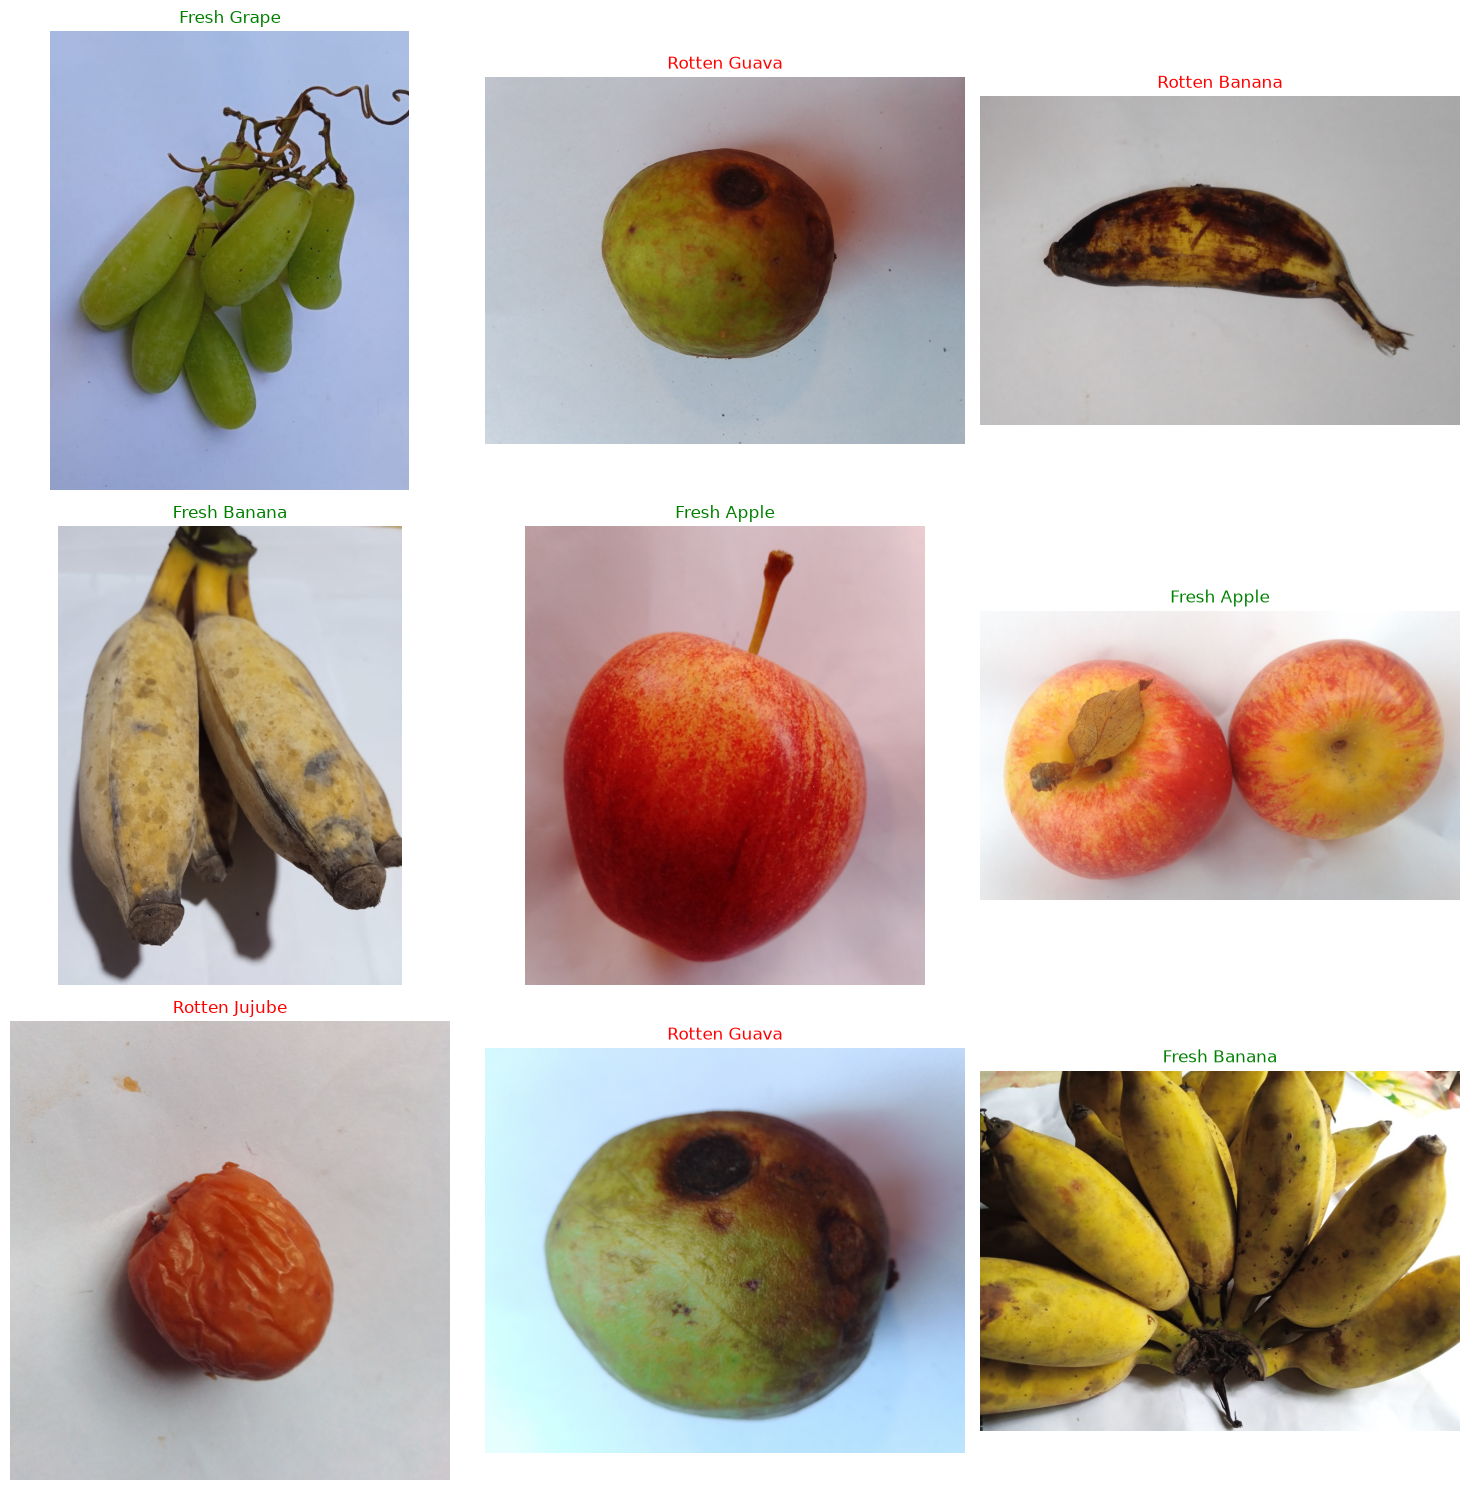

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for ax, path in zip(axes.flat, images_select):
    ax.imshow(Image.open(path))
    name = path.parent.name
    ax.set_title(name.replace("_", " ").title(),
             color="green" if name.startswith("fresh") else "red")

    ax.axis("off")

plt.tight_layout()
plt.show()


## Step 2: Split images inside raw_data/images into training, validation, testing

In [6]:
def group_images_by_class(image_folder:Path) -> tuple[dict, list]:
    image_classes = {}
    for folder in sorted(image_folder.iterdir()):
        if folder.is_dir():
            image_classes[folder.name] = sorted(
                image for image in folder.iterdir()
                if image.suffix.lower() in {".jpg", ".jpeg", ".png"}
                )
    classes = list(image_classes.keys())

    return image_classes, classes

In [7]:
all_images, classes = group_images_by_class(image_folder=image_folder)

def spliting(all_images: dict[str, list], classes: list[str] = None, seed: int = 42):
    """
    Split each class into train/val/test: 65% / 15% / 20%.
    """
    train_df, val_df, test_df = {}, {}, {}
    rng = random.Random(seed)

    for key, value in sorted(all_images.items()):
        items = sorted(value)
        rng.shuffle(items)

        size = len(items)
        train_end = int(size * 0.65)
        val_end = int(size * 0.80)

        train_df[key] = items[:train_end]
        val_df[key] = items[train_end:val_end]
        test_df[key] = items[val_end:]

    return train_df, val_df, test_df, classes

In [8]:
train_df, val_df, test_df, classes = spliting(all_images, classes)

print("Number of Images per classs:")
pd.DataFrame({
    "train": {key: len(value) for key, value in train_df.items()},
    "val":   {key: len(value) for key, value in val_df.items()},
    "test":  {key: len(value) for key, value in test_df.items()},
})


Number of Images per classs:


,train,val,test
fresh_apple,130,30,40
fresh_banana,130,30,40
fresh_grape,130,30,40
fresh_guava,130,30,40
fresh_jujube,130,30,40
fresh_orange,130,30,40
fresh_pomegranate,130,30,40
fresh_strawberry,130,30,40
rotten_apple,130,30,40
rotten_banana,130,30,40


In [9]:
def copy_split(split: dict[str, list], dest_root: Path):
    shutil.rmtree(dest_root, ignore_errors=True)
    jobs = []
    for class_name, files in split.items():
        dest = dest_root / class_name
        dest.mkdir(parents=True, exist_ok=True)
        jobs += [(file, dest / file.name) for file in files]

    with ThreadPoolExecutor(max_workers=3) as pool:
        list(pool.map(lambda job: shutil.copy2(*job), jobs))


In [10]:
data_dir = image_folder.parent.parent
copy_split(train_df, data_dir / "train")
copy_split(val_df,   data_dir / "validation")
copy_split(test_df,  data_dir / "test")
print("Complete...")

Complete...


## Step 3: Processing Images:
- Load images as tensors
- Resize and normalize images
- Augmentation (for training only)
- Speed up data pipeline

### Many of these images may have come from different cameras and may have different size. This step will check the distribution of width and height in all images and decide appropriate strategies. This will be done through the ratio between width and height

In [11]:
rows = []
for class_name, files in all_images.items():
    for path in files:
        with Image.open(path) as image:
            width, height = image.size
        rows.append({
            "class":class_name,
            "fruit":class_name.split("_", 1)[1],
            "state":class_name.split("_", 1)[0],
            "width": width,
            "height":height,
            "aspect_ratio":width / height
        })
sizes = pd.DataFrame(rows)
sizes.describe()

,width,height,aspect_ratio
count,3200.000000,3200.000000,3200.000000
mean,2290.565938,2135.965625,1.084720
std,1064.442339,923.097362,0.251219
min,251.000000,301.000000,0.382372
25%,1200.000000,1260.250000,0.917138
50%,2492.500000,2330.000000,1.066004
75%,3081.000000,2820.000000,1.263836
max,4160.000000,4160.000000,2.519119


### Plotting  distribution by classes

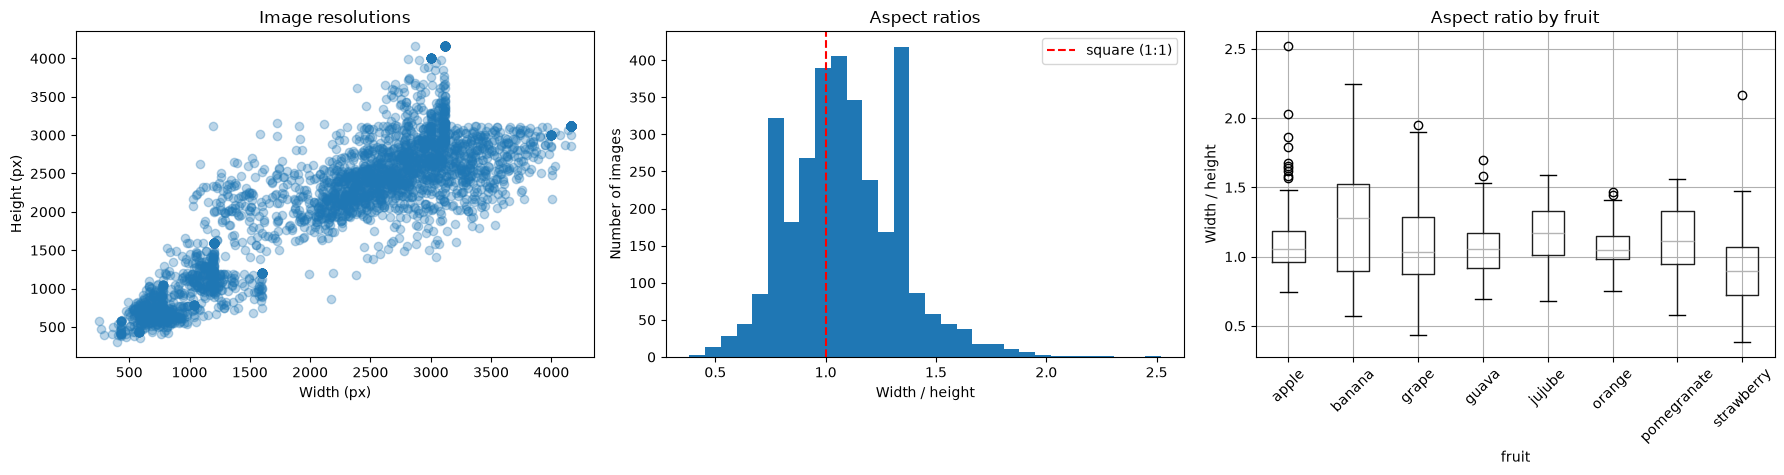

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# width vs height: shows how many distinct resolutions there are
axes[0].scatter(sizes["width"], sizes["height"], alpha=0.3)
axes[0].set(xlabel="Width (px)", ylabel="Height (px)", title="Image resolutions")

# aspect-ratio histogram: 1.0 = square, >1 = wide, <1 = tall
axes[1].hist(sizes["aspect_ratio"], bins=30)
axes[1].axvline(1.0, color="red", linestyle="--", label="square (1:1)")
axes[1].set(xlabel="Width / height", ylabel="Number of images", title="Aspect ratios")
axes[1].legend()

# aspect ratio per fruit: does one fruit come in a different shape?
sizes.boxplot(column="aspect_ratio", by="fruit", ax=axes[2], rot=45)
axes[2].set(title="Aspect ratio by fruit", ylabel="Width / height")

plt.suptitle("")
plt.tight_layout()
plt.show()


Images in this dataset are from different sizes. So resizing them to a fixed size is a required preprocessing step. Stretching images where ratio of width/height between 0.8 to 1.25 distorts images only slighly. Resizing images where ratio lays between 1.33 (4:3) or 1.78 (16:9), typical phone photos size, might make fruits look squashed. crop_to_aspect_ratio=True will be set to center fruits in the middle

In [13]:
sizes.groupby("class")[["width", "height", "aspect_ratio"]].mean().round(2)

,width,height,aspect_ratio
class,,,
fresh_apple,2640.36,2468.68,1.09
fresh_banana,1184.03,1147.54,1.10
fresh_grape,798.37,743.82,1.10
fresh_guava,1215.24,1274.44,0.98
fresh_jujube,2880.14,2518.32,1.15
fresh_orange,3142.46,2892.21,1.10
fresh_pomegranate,2492.30,2455.89,1.03
fresh_strawberry,1850.84,2341.26,0.78
rotten_apple,3099.17,2918.95,1.08


In [14]:
IMAGE_SIZE = (222, 224)
BATCH = 32
train_data = tf.keras.utils.image_dataset_from_directory(
    data_dir/"train",
    image_size=IMAGE_SIZE,
    batch_size=BATCH,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)
val_data = tf.keras.utils.image_dataset_from_directory(
    data_dir/"validation",
    image_size=IMAGE_SIZE,
    batch_size=BATCH,
    label_mode="categorical",
    shuffle=False,
    seed=SEED
    )

test_data = tf.keras.utils.image_dataset_from_directory(
    data_dir/"test",
    image_size=IMAGE_SIZE,
    batch_size=BATCH,
    label_mode="categorical",
    shuffle=False,
    seed=SEED
)
train_data

Found 2080 files belonging to 16 classes.
Found 480 files belonging to 16 classes.
Found 640 files belonging to 16 classes.


E0000 00:00:1795028464.048235  171524 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1795028464.048910  171838 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1795028464.066936  171524 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 222, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 16), dtype=tf.float32, name=None))>

### Augment training set

In [15]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
], name="augmentation")

In [16]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_data.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_data.cache().prefetch(AUTOTUNE)
test_ds  = test_data.cache().prefetch(AUTOTUNE)

In [17]:
def mobilenet_model():
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(222, 224, 3),
        include_top=False,
        weights="imagenet",
    )
    base_model.trainable = False
    inputs = tf.keras.Input(shape=(222, 224, 3))
    x = augment(inputs)
    x = tf.keras.layers.Rescaling(1/127.5, offset=-1)(x)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAvgPool2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(len(classes), activation="softmax")(x)
    
    model = tf.keras.Model(inputs, outputs, name="freshness_mobilenet")
    return model

model = mobilenet_model()
model.summary()

/tmp/ipykernel_171524/2249496710.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


Model: "freshness_mobilenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 222, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 222, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 222, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        20,496 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,278,480 (8.69 MB)

 Trainable params: 20,496 (80.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
def compile_model(model:tf.keras.Model):
    """Compile the model and run"""
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="Precision"),
            tf.keras.metrics.Recall(name="Recall"),
            #tf.keras.metrics.AUC(name="AUC", multi_label=True),
            tf.keras.metrics.F1Score(average="macro", name="F1Score", )
        ]        
    )
    return model

In [ ]:
def get_callbacks(log_roots="logs"):
    """This function runs callback functions to monitor training"""
    model_dir = Path().cwd().resolve().parent/"models"/log_roots
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            min_delta=0.002,
            restore_best_weights=True
        ),
        tf.keras.callbacks.TensorBoard(
            log_dir=model_dir,
            histogram_freq=1
            ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-8
            ),
        tf.keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_loss", save_best_only=True)
    ]


In [20]:
def run_model(model:tf.keras.Model):
    """
    This function runs model
    """
    model = compile_model(model=model)
    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=30,
        callbacks=get_callbacks()
    )
    return history

In [ ]:
history = run_model(model=model)

Epoch 1/30


/home/bode-murairi/Documents/programming/ml/assignments/freshness-ai/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


65/65 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - F1Score: 0.5949 - Precision: 0.9143 - Recall: 0.3591 - accuracy: 0.5938 - loss: 1.6363 - val_F1Score: 0.8465 - val_Precision: 0.9587 - val_Recall: 0.6771 - val_accuracy: 0.8479 - val_loss: 1.0294 - learning_rate: 0.0010
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - F1Score: 0.8752 - Precision: 0.9556 - Recall: 0.7442 - accuracy: 0.8760 - loss: 0.9739 - val_F1Score: 0.8940 - val_Precision: 0.9607 - val_Recall: 0.8146 - val_accuracy: 0.8958 - val_loss: 0.9136 - learning_rate: 0.0010
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - F1Score: 0.9289 - Precision: 0.9724 - Recall: 0.8313 - accuracy: 0.9293 - loss: 0.8750 - val_F1Score: 0.9146 - val_Precision: 0.9626 - val_Recall: 0.8583 - val_accuracy: 0.9167 - val_loss: 0.8581 - learning_rate: 0.0010
Epoch 4/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - F1Score: 0.9335 - Precision: 0.9734 - Recall: 0.8611 - accuracy: 0.9337 - loss: 0.8366 - val_F1Score: 0.9251 - val_Precision: 0.9701 - val_Reca

In [ ]:
def plot_history(history):
    h = history.history
    metrics = ["loss", "accuracy", "Precision", "Recall", "F1Score"]
    epochs = range(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1      # epoch with lowest val loss

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))

    for ax, metric in zip(axes.flat, metrics):
        ax.plot(epochs, h[metric], label="train")
        ax.plot(epochs, h[f"val_{metric}"], label="validation")
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
        ax.set(title=metric, xlabel="Epoch")
        ax.grid(alpha=0.3)
        ax.legend()

    # 6th panel: learning rate (shows when ReduceLROnPlateau kicked in)
    axes.flat[5].plot(epochs, h["learning_rate"], color="purple")
    axes.flat[5].set(title="Learning rate", xlabel="Epoch", yscale="log")
    axes.flat[5].grid(alpha=0.3)

    plt.suptitle("Training vs validation metrics", fontsize=16)
    plt.tight_layout()
    plt.show()

plot_history(history=history)


In [23]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 186905), started 0:00:34 ago. (Use '!kill 186905' to kill it.)